### Build a Domain Specific RAG

XYZ AI Solutions manages an extensive ecosystem of developer tools. Currently, our internal support engineers and community managers spend over 40% of their day navigating fragmented documentation to answer technical questions about HuggingFace-based workflows. The existing keyword search is insufficient, often failing to capture the nuance of complex machine learning queries, leading to high support ticket latency and inconsistent developer advice.

**The Goal:** Your goal is to implement a robust, end-to-end RAG pipeline. In an industry setting, success is measured not just by code execution, but by the reliability and relevance of the retrieved information.

**The Solution:** As part of the RAG (Retrieval-Augmented Generation) task force, you are tasked with building a Production-Grade Knowledge Retrieval System. This system must ingest documentation, store it in a high-performance vector database, and provide context-aware answers to complex queries using an LLM.


**Objective**
The objective of this note book is to create an end-to-end RAG Pipeline on the dataset. So, the users can integrate this RAG pipeline to get the answers for the queries.

**RAG Implementation Steps**
1.   Load the data & analyze it.
2.   Chunk the data
3.   Vectorize:- Generate the embeddings for each chunk
4.   Store:- Store these embeddings in Vector DB
5.   Retrieval:- Retrieve the relevant chunks(docs) for the query embedding
6.   Generation:- Generate the answer using the retrieved chunk by calling an LLM
7.   Evaluation:- Evaluate the Retrieval results & Generated Answer
8.   RAG Pipeline:- Finalize RAG pipeline with the best parameters.




**NOTE**

This notebook uses Huggingface & OpenAI API tokens. When running the notebook it will ask for you to enter at run time. So, kindly enter it to run the notebook seamlessly.

Also, Running this notebook on GPU is preferred as it will help in decreasing the processing time for LLM's used in this cases study.

In [1]:
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'

print(device)

cuda


In [2]:
import os
import getpass

os.environ['HF_TOKEN'] = getpass.getpass('Enter the Hugging Face Token: ')

Enter the Hugging Face Token: ··········


In [3]:
# Install dependencies
!pip install -q pymilvus[milvus_lite] sentence-transformers datasets transformers torch accelerate opik tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.7/159.7 kB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.9/71.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.1/28.1 MB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 269.6/269.6 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 48.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.1/668.1 kB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.7/99.7 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.0/345.0 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.7

# Stage 1: Chunking the Knowledge Base

### Task 1.1: Load the HuggingFace doc dataset and inspect its structure

In [4]:
# Loading the Dataset
from datasets import load_dataset

# Load the HuggingFace documentation dataset
dataset = load_dataset("m-ric/huggingface_doc", split="train")

print(f"Dataset loaded with {len(dataset)} documents")
print(f"Columns: {dataset.column_names}")
print(f"\nSample document (first 500 chars):")
print(dataset[0]["text"][:500])


README.md:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

huggingface_doc.csv: reconstructing file:   0%|          |  0.00B / 22.0MB            

huggingface_doc.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2647 [00:00<?, ? examples/s]

Dataset loaded with 2647 documents
Columns: ['text', 'source']

Sample document (first 500 chars):
 Create an Endpoint

After your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english) for text classification. 

## 1. Enter the Hugging Face Repository ID and your desired endpoint name:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-docu


In [5]:
# Extract text and source information
documents = []
for item in dataset:
    documents.append({
        "text": item["text"],
        "source": item["source"]
    })

print(f"Extracted {len(documents)} documents")

Extracted 2647 documents


In [6]:
import pandas as pd
df = pd.DataFrame(columns = ['source', 'text'], data = documents)
#df = pd.read_csv('RAG_BCS_Dataset.csv')
df.head()

,source,text
0,huggingface/hf-endpoints-documentation/blob/ma...,"Create an Endpoint\n\nAfter your first login,..."
1,huggingface/evaluate/blob/main/docs/source/cho...,Choosing a metric for your task\n\n**So you'v...
2,gradio-app/gradio/blob/main/guides/cn/01_getti...,主要特点\n\n让我们来介绍一下 Gradio 最受欢迎的一些功能！这里是 Gradio ...
3,huggingface/transformers/blob/main/docs/source...,!--Copyright 2023 The HuggingFace Team. All ri...
4,gradio-app/gradio/blob/main/demo/blocks_random...,Gradio Demo: blocks_random_slider\n\n\n```\n!...


In [7]:
print('Shape of dataset', df.shape)

Shape of dataset (2647, 2)


In [8]:
print('Count of documnents:', len(df))

Count of documnents: 2647


In [9]:
print('Sample Document')
print('--'*50)
print(df['text'][0])

Sample Document
----------------------------------------------------------------------------------------------------
 Create an Endpoint

After your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english) for text classification. 

## 1. Enter the Hugging Face Repository ID and your desired endpoint name:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_repository.png" alt="select repository" />

## 2. Select your Cloud Provider and region. Initially, only AWS will be available as a Cloud Provider with the `us-east-1` and `eu-west-1` regions. We will add Azure soon, and if you need to test Endpoints with other Cloud Providers or regions, please let us know.

<img src="https://raw.githubusercontent.com/hugg

In [10]:
#Creating the length_of_text column inspect how texts are distributed in the dataset
df['length_of_text'] = df['text'].apply(lambda x: len(x))

In [11]:
#It provides the stats on how length of texts are distributed
df['length_of_text'].describe()

,length_of_text
count,2647.000000
mean,8079.177937
std,15850.725597
min,23.000000
25%,1915.000000
50%,4575.000000
75%,9249.500000
max,371057.000000


In [12]:
df['length_of_text'].quantile(0.2)

np.float64(1478.0000000000002)

Based on the above stats & distribution, We can start with chunk_size as 1500 characters that way more thank 80% of texts will be divided in to chunks & with overlap size of 30% of the chunk_size i.e., 500

### Task 1.2: Implement a sliding-window chunking function that takes chunk_size and chunk_overlap as parameters and walks each document, producing overlapping text chunks.

Created 2 chunking methods with overlap.
Method#1. chunk_document:- It splits the text/document into overlapping chunks of fixed size
Method#2. recursive_chunker:- Recursively splits text using a list of separators["\n\n", "\n", " ", ""], then merges small splits into chunks up to chunk_size with overlap.

In [13]:
def chunk_document(text: str, chunk_size: int = 1000, chunk_overlap: int = 200) -> list[str]:
    """
    Split a document into overlapping chunks of fixed size.

    Args:
        text: The document text to chunk
        chunk_size: Maximum size of each chunk in characters
        chunk_overlap: Number of overlapping characters between chunks

    Returns:
        List of text chunks
    """
    chunks = []

    if text == None or len(text.strip()) == 0:
      pass
    if len(text) < chunk_size:
      chunks.append(text)

    # Calculate step size for sliding window
    step = chunk_size - chunk_overlap
    text = text.strip()
    chunk = ""
    for i in range(0, len(text), step):
       chunk =  "".join(text[i:i+chunk_size])
       if len(chunk.strip()) > 0:
        chunks.append(chunk.strip())

    return chunks

In [14]:
def recursive_chunker(
    text: str,
    chunk_size: int = 500,
    overlap: int = 100,
    separators: list[str] = None
) -> list[str]:
    """
    Recursively splits text using a list of separators, then merges small
    splits into chunks up to `chunk_size` with `overlap`.
    """
    if separators is None:
        separators = ["\n\n", "\n", " ", ""]

    # 1. Base recursive function to split text down to small enough units
    def _split_text(text_to_split: str, current_separators: list[str]) -> list[str]:
        if not text_to_split:
            return []

        # If text is already smaller than chunk size, no need to split further
        if len(text_to_split) <= chunk_size:
            return [text_to_split]

        # Find the first separator available in current_separators
        sep = current_separators[-1] if not current_separators else current_separators[0]
        next_separators = current_separators[1:] if len(current_separators) > 1 else []

        for s in current_separators:
            if s == "" or s in text_to_split:
                sep = s
                next_separators = current_separators[current_separators.index(s) + 1:]
                break

        # Split by the chosen separator
        if sep != "":
            splits = text_to_split.split(sep)
            # Re-add separator to preserve structure
            splits = [s + sep for s in splits[:-1]] + [splits[-1]]
            splits = [s for s in splits if s]
        else:
            # Fallback to character-by-character splitting
            splits = list(text_to_split)

        # Recursively split any sub-piece that exceeds chunk_size
        final_splits = []
        for split in splits:
            if len(split) > chunk_size and next_separators:
                final_splits.extend(_split_text(split, next_separators))
            else:
                final_splits.append(split)

        return final_splits

    # Get initial atomic pieces
    raw_splits = _split_text(text, separators)

    # 2. Merge atomic pieces into chunks with target size and overlap
    chunks = []
    current_chunk = []
    current_length = 0

    for split in raw_splits:
        split_len = len(split)

        # If adding this split exceeds chunk_size, finalize the current chunk
        if current_length + split_len > chunk_size and current_chunk:
            chunk_str = "".join(current_chunk).strip()
            if chunk_str:
                chunks.append(chunk_str)

            # Keep pieces from the end of current_chunk to satisfy overlap
            overlap_pieces = []
            overlap_len = 0
            for piece in reversed(current_chunk):
                if overlap_len + len(piece) <= overlap:
                    overlap_pieces.insert(0, piece)
                    overlap_len += len(piece)
                else:
                    break

            current_chunk = overlap_pieces
            current_length = overlap_len

        current_chunk.append(split)
        current_length += split_len

    # Add remaining text if present
    if current_chunk:
        chunk_str = "".join(current_chunk).strip()
        if chunk_str:
            chunks.append(chunk_str)

    return chunks

In [15]:
!pip install chonkie

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.8/233.8 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.4/386.4 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 48.9 MB/s eta 0:00:00


In [16]:
from chonkie import Visualizer
viz = Visualizer()

In [17]:
chunks = chunk_document(df['text'][0], chunk_size=1500, chunk_overlap=500)
len(chunks)

3

In [18]:
viz.print(chunks)

Create an Endpoint

After your first login, you will be directed to the [Endpoint creation 
page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy 
[distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-en
glish) for text classification. 

## 1. Enter the Hugging Face Repository ID and your desired endpoint name:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_repository.png" 
alt="select repository" />

## 2. Select your Cloud Provider and region. Initially, only AWS will be available as a Cloud Provider with the 
`us-east-1` and `eu-west-1` regions. We will add Azure soon, and if you need to test Endpoints with other Cloud 
Providers or regions, please let us know.

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_region.png" 
alt="select region" />

## 3. Define the [Security Level](security) for the Endpoint:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_security.png" 
alt="define security" />

## 4. Create your Endpoint by clicking **Create Endpoint**. By default, your Endpoint is created with a medium CPU 
(2 x 4GB vCPUs with Intel Xeon Ice Lake) The cost estimate assumes the Endpoint will be up for an entire month, and
does not take autoscaling into account.

<img src="https://raw.githubusercontent.com/huggingface/hf-en(security) for the Endpoint:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_security.png" 
alt="define security" />

## 4. Create your Endpoint by clicking **Create Endpoint**. By default, your Endpoint is created with a medium CPU 
(2 x 4GB vCPUs with Intel Xeon Ice Lake) The cost estimate assumes the Endpoint will be up for an entire month, and
does not take autoscaling into account.

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_create_cost.png" 
alt="create endpoint" />

## 5. Wait for the Endpoint to build, initialize and run which can take between 1 to 5 minutes.

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/overview.png" 
alt="overview" />

## 6. Test your Endpoint in the overview with the Inference widget 🏁 🎉!

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_inference.png" 
alt="run inference" />ference" />

In [19]:
chunks = recursive_chunker(df['text'][0], chunk_size=1500, overlap=500)
len(chunks)

2

In [20]:
viz.print(chunks)

Create an Endpoint

After your first login, you will be directed to the [Endpoint creation 
page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy 
[distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-en
glish) for text classification. 

## 1. Enter the Hugging Face Repository ID and your desired endpoint name:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_repository.png" 
alt="select repository" />

## 2. Select your Cloud Provider and region. Initially, only AWS will be available as a Cloud Provider with the 
`us-east-1` and `eu-west-1` regions. We will add Azure soon, and if you need to test Endpoints with other Cloud 
Providers or regions, please let us know.

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_region.png" 
alt="select region" />

## 3. Define the [Security Level](security) for the Endpoint:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_security.png" 
alt="define security" />

## 4. Create your Endpoint by clicking **Create Endpoint**. By default, your Endpoint is created with a medium CPU 
(2 x 4GB vCPUs with Intel Xeon Ice Lake) The cost estimate assumes the Endpoint will be up for an entire month, and
does not take autoscaling into account.## 3. Define the [Security Level](security) for the Endpoint:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_security.png" 
alt="define security" />

## 4. Create your Endpoint by clicking **Create Endpoint**. By default, your Endpoint is created with a medium CPU 
(2 x 4GB vCPUs with Intel Xeon Ice Lake) The cost estimate assumes the Endpoint will be up for an entire month, and
does not take autoscaling into account.

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_create_cost.png" 
alt="create endpoint" />

## 5. Wait for the Endpoint to build, initialize and run which can take between 1 to 5 minutes.

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/overview.png" 
alt="overview" />

## 6. Test your Endpoint in the overview with the Inference widget 🏁 🎉!

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_inference.png" 
alt="run inference" />

When i compared the chunks that created using chunk_document & recursive_chunker using chonkie visualizer in colab. I saw the recursive_chunker created more effective chunks with overlap. So, Will create the chunks using this method.

### Task 1.3: Attach lineage metadata (a unique chunk_id and the parent source) to every chunk so it can be traced back to its original document.

Created the below method that takes the dataset as input, chunks all the documents & returns a List[Dict] with keys as 'text', 'source', 'chunk_id' and 'source_id'.

In [21]:
def chunk_all_documents(documents, chunk_size: int = 1000, chunk_overlap: int = 200) -> list[dict]:
    """
    Chunk all documents and preserve metadata.

    Args:
        documents: List of document dicts with 'text' and 'source' keys
        chunk_size: Maximum chunk size
        chunk_overlap: Overlap between chunks

    Returns:
        List of chunk dicts with 'text', 'source', 'chunk_id' and 'source_id' keys
    """
    all_chunks = []
    chunk_id = 0

    for i in range(len(documents)):
      text = documents['text'][i]
      source = documents['source'][i]
      #chunks = chunk_document(text, chunk_size, chunk_overlap)
      chunks = recursive_chunker(text, chunk_size, chunk_overlap)
      for j in range(len(chunks)):
        chunk_id += 1
        chunk = {
            'chunk_id': chunk_id,
            'source': source,
            'text': chunks[j],
            'source_id': i+1
        }
        all_chunks.append(chunk)

    return all_chunks

### Task 1.4: Run the chunker across the full dataset and report chunk counts and average chunks-per-document.

In [22]:
CHUNK_SIZE = 1500
CHUNK_OVERLAP = 500

chunks = chunk_all_documents(
        documents = df,
        chunk_size = CHUNK_SIZE ,
        chunk_overlap = CHUNK_OVERLAP
    )

In [23]:
print(f"\nCreated {len(chunks)} chunks from {len(df)} documents")
print(f"Average chunks per document: {len(chunks) / len(df):.2f}")



Created 21192 chunks from 2647 documents
Average chunks per document: 8.01


In [24]:
# Show sample chunk
if chunks:
    print(f"\nSample chunk:")
    print(f"  ID: {chunks[21191]['chunk_id']}")
    print(f"  Source_Id: {chunks[21191]['source_id']}")
    print(f"  Source: {chunks[21191]['source']}")
    print(f"  Text: {chunks[21191]['text']}")


Sample chunk:
  ID: 21192
  Source_Id: 2647
  Source: gradio-app/gradio/blob/main/demo/json_component/run.ipynb
  Text: Gradio Demo: json_component


```
!pip install -q gradio 
```


```
import gradio as gr 

with gr.Blocks() as demo:
    gr.JSON(value={"Key 1": "Value 1", "Key 2": {"Key 3": "Value 2", "Key 4": "Value 3"}, "Key 5": ["Item 1", "Item 2", "Item 3"]})

demo.launch()
```


# Stage 2: Vectorizing & Storing Knowledge

### Task 2.1: Choose and load an embedding model, then batch-encode all chunks (rather than one at a time) to keep memory and throughput manageable.

In [25]:
from sentence_transformers import SentenceTransformer

# Load the embedding model
EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"
#EMBEDDING_MODEL = "BAAI/bge-base-en-v1.5"
embedding_model = SentenceTransformer(EMBEDDING_MODEL, device = device)

print(f"Loaded embedding model: {EMBEDDING_MODEL}")

# Test embedding
test_embedding = embedding_model.encode(["This is a test"], normalize_embeddings=True)
EMBEDDING_DIM = len(test_embedding[0])
print(f"Embedding dimension: {EMBEDDING_DIM}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded embedding model: BAAI/bge-small-en-v1.5
Embedding dimension: 384


### Task 2.2: Apply vector normalization during encoding so similarity search behaves consistently.

In [26]:
def generate_embeddings(texts: list[str], model: SentenceTransformer, batch_size: int = 32) -> list[list[float]]:
    """
    Generate embeddings for a list of texts.

    Args:
        texts: List of text strings to embed
        model: SentenceTransformer model
        batch_size: Number of texts to process at once

    Returns:
        List of embedding vectors (as lists of floats)
    """
    all_embeddings = []

    for i in range(0, len(texts), batch_size):
      batch = texts[i:i+batch_size]
      batch_embeddings = model.encode(
          batch,
          normalize_embeddings = True
      )
      all_embeddings.extend(batch_embeddings.tolist())

    return all_embeddings

In [27]:
# Generate embeddings for all chunks
chunk_texts = [chunk["text"] for chunk in chunks]
embeddings = generate_embeddings(chunk_texts, embedding_model)

print(f"\nGenerated {len(embeddings)} embeddings")
if embeddings:
    print(f"Embedding dimension: {len(embeddings[0])}")
    print(f"Sample embedding (first 10 values): {embeddings[0][:10]}")


Generated 21192 embeddings
Embedding dimension: 384
Sample embedding (first 10 values): [-0.07339438796043396, -0.03978276252746582, -0.039712049067020416, -0.029718229547142982, 0.045156922191381454, 0.037254758179187775, -0.06225801631808281, -0.04653097689151764, -0.0415283627808094, 0.025291163474321365]


### Task 2.3: Set up a vector database collection with the correct dimensionality and similarity metric for your normalized vectors, handling the case where the collection already exists.

Storing embeddings in Milvus VectorDB


In [28]:
from pymilvus import MilvusClient

# Initialize Milvus client (uses Milvus Lite - stores data locally)
MILVUS_DB_PATH = "./hf_docs_milvus.db"
milvus_client = MilvusClient(uri=MILVUS_DB_PATH)

COLLECTION_NAME = "hf_documentation"

print(f"Milvus client initialized with database: {MILVUS_DB_PATH}")

Milvus client initialized with database: ./hf_docs_milvus.db


In [29]:
def setup_milvus_collection(client: MilvusClient, collection_name: str, embedding_dim: int):
    """
    Create a Milvus collection for storing document embeddings.

    Args:
        client: MilvusClient instance
        collection_name: Name of the collection to create
        embedding_dim: Dimension of the embedding vectors
    """
    #Drop the collection if it already exists
    if client.has_collection(collection_name):
      client.drop_collection(collection_name)

    #Create new collection
    client.create_collection(
        collection_name = collection_name,
        dimension = embedding_dim,
        metric_type = "IP",
        consistency_level = "Strong"
      )

    print(f"Created collection: {collection_name} with dimension {embedding_dim}")

In [30]:
# Setup the collection
setup_milvus_collection(milvus_client, COLLECTION_NAME, EMBEDDING_DIM)

ERROR:grpc._server:Exception calling application: Method not implemented!
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/grpc/_server.py", line 608, in _call_behavior
    response_or_iterator = behavior(argument, context)
  File "/usr/local/lib/python3.13/dist-packages/pymilvus/grpc_gen/milvus_pb2_grpc.py", line 1357, in AllocTimestamp
    raise NotImplementedError('Method not implemented!')
NotImplementedError: Method not implemented!


Created collection: hf_documentation with dimension 384


### Task 2.4: Insert all chunk vectors and metadata into the collection in batches, and confirm every record was inserted

In [31]:
def insert_data_to_milvus(
    client: MilvusClient,
    collection_name: str,
    chunks: list[dict],
    embeddings: list[list[float]],
    batch_size: int = 100
):
    """
    Insert document chunks and embeddings into Milvus.

    Args:
        client: MilvusClient instance
        collection_name: Name of the collection
        chunks: List of chunk dictionaries with text and metadata
        embeddings: List of embedding vectors
        batch_size: Number of records to insert at once

    Returns:
        Total number of inserted records
    """
    total_inserted = 0

    # Prepare data as a list of dictionaries, where each dict has:
    #   - "id": chunk["chunk_id"]
    #   - "vector": the corresponding embedding
    #   - "text": chunk["text"]
    #   - "source": chunk["source"]
    #   - "source_id": chunk["source_id"]
    milvus_chunks = []
    for i in range(len(chunks)):
      milvus_chunk = {
          'id': chunks[i]['chunk_id'],
          'vector': embeddings[i],
          'text': chunks[i]['text'],
          'source': chunks[i]['source'],
          'source_id': chunks[i]['source_id']
      }
      milvus_chunks.append(milvus_chunk)

    # Insert in batches using client.insert()
    for i in range(0, len(milvus_chunks), batch_size):
      batch = milvus_chunks[i:i+batch_size]
      result = client.insert(collection_name = collection_name, data = batch)
      total_inserted += result['insert_count']

    return total_inserted

`insert_data_to_milvus` method inserts chunks & metadata into milvus collection in batches.

In [32]:
# Insert data into Milvus
inserted_count = insert_data_to_milvus(milvus_client, COLLECTION_NAME, chunks, embeddings)

print(f"\nInserted {inserted_count} records into Milvus")

if inserted_count == len(chunks):
    print("✅ All chunks inserted successfully!")
else:
    print("❌ Not all chunks were inserted. Check your implementation.")


Inserted 21192 records into Milvus
✅ All chunks inserted successfully!


# Stage 3: Retrieving Relevant Context

In [33]:
from sentence_transformers import CrossEncoder
reranker_bge = CrossEncoder("BAAI/bge-reranker-v2-m3", device = device)

config.json:   0%|          | 0.00/795 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

In [34]:
from sentence_transformers import CrossEncoder
reranker_minilm = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", device = device)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

### Task 3.1: Encode an incoming query using the exact same embedding process (including normalization) used during indexing.

In [35]:
test_query = "How do I fine-tune a transformer model?"

instruction = 'Represent this Sentence for Searchin relevant passages: '

query_embeddings = embedding_model.encode([instruction+test_query], normalize_embeddings= True)

print('Length of query_embeddings:',len(query_embeddings[0]))
query_embeddings[0][:10]

Length of query_embeddings: 384


array([-0.08717589,  0.03547673,  0.05123246, -0.03639361, -0.04326978,
       -0.03312429, -0.08033115,  0.02280885,  0.02879203,  0.05680301],
      dtype=float32)

### Task 3.2: Search the vector database with a configurable top_k and matching similarity metric, requesting the text and source fields back.

Created the `retrieve_documents` method to retrieve top_k documents from the milvus vector db along with similarity scores & source.

In [36]:
def retrieve_documents(
    query: str,
    client: MilvusClient,
    collection_name: str,
    embedding_model: SentenceTransformer,
    top_k: int = 5,
    reranker: CrossEncoder = reranker_bge,
) -> list[dict]:
    """
    Retrieve the most relevant documents for a query.

    Args:
        query: The search query
        client: MilvusClient instance
        collection_name: Name of the collection to search
        embedding_model: Model to generate query embedding
        top_k: Number of results to return
        reranker: Model used to rerank the retrieved chunks

    Returns:
        List of dictionaries with 'id', 'text', 'source', 'source_id', 'retriever_score' & 'reranker_score' keys
    """
    retrieved_docs = []

    #Adding the instruction to the query to create better query embeddings
    instruction = "Represent this Sentence for Searching relevant passages: "

    # Generate embedding for the query
    query_embedding = embedding_model.encode([instruction+query], normalize_embeddings = True).tolist()[0]

    # Search in Milvus using client.search() and pick the 50 best matches
    results = client.search(
        collection_name = collection_name,
        data = [query_embedding],
        limit = 50,
        search_params = {"metric_type": "IP", "params": {}},
        output_fields = ['text', 'source', 'source_id']
    )

    # Format results as list of dicts
    for hits in results:
      for result in hits:
        doc = {
          'id': result['id'],
          'text': result['entity']['text'],
          'source': result['entity']['source'],
          'source_id': result['entity']['source_id'],
          'retriever_score': result['distance']
        }
        retrieved_docs.append(doc)

    #Rank the results from retriever & pick the best top_k

    #create pairs of query & text to be sent to ranker
    pairs = [(query, doc['text']) for doc in retrieved_docs]

    #call the reranker with get scores of pairs
    scores = reranker.predict(pairs, batch = 32)

    #store these scores in the retrieved_docs
    for doc,score in zip(retrieved_docs, scores):
        doc['reranker_score'] = score

    #sort the retrieved_docs based on reranker score
    retrieved_docs.sort(
        key = lambda doc: doc['reranker_score'],
        reverse = True
    )

    #pick the top_k docs with high scores from rereanker
    return retrieved_docs[:top_k]

### Task 3.3: Test retrieval against at least one sample query and inspect the ranked results and their similarity scores.

In [37]:
#Method to display the retrieved documents
def display_retrieved_documents(retrieved):
  for i, doc in enumerate(retrieved):
      print(f"\n--- Document {i+1} ---")
      print(f'Reranker Score: {doc.get('reranker_score', 'N/A')}...')
      print(f"Score: {doc.get('retriever_score', 'N/A')})")
      print(f"Id: {doc.get('id', 'N/A')}")
      print(f"Source Id: {doc.get('source_id', 'N/A')}")
      print(f"Source: {doc.get('source', 'N/A')}")
      print(f"Text: {doc.get('text', 'N/A')}...")

In [38]:
test_query = "How do i create a pipeline in Transformers model?"

# Test retrieval using bge reranker
retrieved = retrieve_documents(
    query=test_query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    top_k=3,
    reranker=reranker_bge
)

print(f"Query: {test_query}")
print(f"\nRetrieved {len(retrieved)} documents")

#Display the documents retrieved from the Milvus VectoDB for our test query
display_retrieved_documents(retrieved)

Query: How do i create a pipeline in Transformers model?

Retrieved 3 documents

--- Document 1 ---
Reranker Score: 0.9885974526405334...
Score: 0.8160728216171265)
Id: 19313
Source Id: 2394
Source: huggingface/transformers/blob/main/docs/source/en/add_new_pipeline.md
Text: ```py
from transformers import pipeline

classifier = pipeline(model="{your_username}/test-dynamic-pipeline", trust_remote_code=True)
```

## Add the pipeline to 🤗 Transformers

If you want to contribute your pipeline to 🤗 Transformers, you will need to add a new module in the `pipelines` submodule
with the code of your pipeline, then add it to the list of tasks defined in `pipelines/__init__.py`.

Then you will need to add tests. Create a new file `tests/test_pipelines_MY_PIPELINE.py` with examples of the other tests.

The `run_pipeline_test` function will be very generic and run on small random models on every possible
architecture as defined by `model_mapping` and `tf_model_mapping`.

This is very important to te

In [39]:
test_query = "How do i create a pipeline in Transformers model?"

# Test retrieval using minilm reranker
retrieved = retrieve_documents(
    query=test_query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    top_k=3,
    reranker=reranker_minilm
)

print(f"Query: {test_query}")
print(f"\nRetrieved {len(retrieved)} documents")

#Display the documents retrieved from the Milvus VectoDB & reranked using minilm reranker
display_retrieved_documents(retrieved)

Query: How do i create a pipeline in Transformers model?

Retrieved 3 documents

--- Document 1 ---
Reranker Score: 7.612552642822266...
Score: 0.8160728216171265)
Id: 19313
Source Id: 2394
Source: huggingface/transformers/blob/main/docs/source/en/add_new_pipeline.md
Text: ```py
from transformers import pipeline

classifier = pipeline(model="{your_username}/test-dynamic-pipeline", trust_remote_code=True)
```

## Add the pipeline to 🤗 Transformers

If you want to contribute your pipeline to 🤗 Transformers, you will need to add a new module in the `pipelines` submodule
with the code of your pipeline, then add it to the list of tasks defined in `pipelines/__init__.py`.

Then you will need to add tests. Create a new file `tests/test_pipelines_MY_PIPELINE.py` with examples of the other tests.

The `run_pipeline_test` function will be very generic and run on small random models on every possible
architecture as defined by `model_mapping` and `tf_model_mapping`.

This is very important to tes

# Stage 4: Grounded Answer Generation

### Task 4.1: Design a prompt template that instructs the LLM to answer only from the provided context and to explicitly say when it doesn't have enough information.

In [40]:
#Prompt Template for Generate answer using LLM
PROMPT_TEMPLATE = """You are answering questions using ONLY information from the provided documents.

CRITICAL RULES:
1. Every fact in your answer MUST come directly from the documents below
2. If the documents don't contain enough information to answer the question, you MUST say so
3. DO NOT use any knowledge from your training data
4. DO NOT make inferences beyond what is explicitly stated
5. DO NOT fill in gaps with plausible-sounding information

DOCUMENTS:
{context}

QUESTION: {question}

Provide your answer following the rules above."""

### Task 4.2: Implement a generation function that joins retrieved chunks into a context block, formats the prompt, and calls the LLM.

In this case study, I will be using OpenAI LLM - `gpt-4o-mini` for generating the answer to our query with documents retrieved from vectordb.

In [41]:
os.environ["OPENAI_API_KEY"] = getpass.getpass("Enter your OpenAI API key: ")

Enter your OpenAI API key: ··········


In [42]:
from openai import OpenAI
openai_client = OpenAI()

In [43]:
def generate_answer(
    query: str,
    retrieved_docs: list[dict],
    openai_client: OpenAI,
    max_new_tokens: int = 500
) -> dict:
    """
    Generate an answer using retrieved documents as context.

    Args:
        query: The user's question
        retrieved_docs: List of retrieved document dictionaries
        openai_client: OpenAI Client
        max_new_tokens: Maximum tokens to generate

    Returns:
        Dictionary with 'answer', 'context', 'query', and 'retrieved_docs'
    """

    context = ""
    answer = ""

    # Combine retrieved documents into context
    context = "\n\n".join([doc["text"] for doc in retrieved_docs])

    # Format the prompt using PROMPT_TEMPLATE
    prompt = PROMPT_TEMPLATE.format(context = context, question = query)

    # Generate response
    outputs = openai_client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {"role": "user", "content": prompt}
        ],
        temperature=0.0,
        max_tokens=max_new_tokens
    )

    #Extract the generated text
    answer = outputs.choices[0].message.content.strip()

    return {
        "query": query,
        "answer": answer,
        "context": context,
        "retrieved_docs": retrieved_docs
    }

### Task 4.3: Compose retrieval and generation into a single end-to-end function so a caller can go from raw query to final answer in one call.

In [44]:
# Complete RAG pipeline function

def rag_query(
    query: str,
    client: MilvusClient,
    collection_name: str,
    embedding_model: SentenceTransformer,
    openai_client: OpenAI,
    top_k: int = 5,
    reranker: CrossEncoder = reranker_bge,
    max_new_tokens: int = 256
) -> dict:
    """
    Complete RAG pipeline: retrieve then generate.
    """
    # Retrieve
    retrieved_docs = retrieve_documents(
        query=query,
        client=milvus_client,
        collection_name=collection_name,
        embedding_model=embedding_model,
        top_k=top_k,
        reranker=reranker
    )

    # Generate
    result = generate_answer(
        query=query,
        retrieved_docs=retrieved_docs,
        openai_client = openai_client,
        max_new_tokens=max_new_tokens
    )

    return result

In [45]:
def display_answer(result):
    print(f"\n{'='*60}")
    print(f"Q: {result['query']}")
    print(f"A: {result['answer']}")

### Task 4.4: Test the full pipeline against several distinct queries spanning different parts of the documentation.

In [46]:
# Test complete pipeline with multiple queries
test_queries = [
    "What is the Trainer class in transformers?",
    "How do I load a dataset from HuggingFace?",
    "How do i create a dataframe in Pandas?",
    "How do i save the dataframe in HuggingFace?",
    "What is the capital of Telangana?",
    "Give me an example of Gradio?",
    "How do i create a pipeline in Transformers model?"
]

for query in test_queries:
    result = rag_query(
        query=query,
        client=milvus_client,
        collection_name=COLLECTION_NAME,
        embedding_model=embedding_model,
        openai_client = openai_client,
        top_k=3,
        reranker=reranker_bge
    )
    display_answer(result)


Q: What is the Trainer class in transformers?
A: The Trainer class in the Transformers library is a complete training and evaluation loop for PyTorch models. It requires you to pass the necessary components for training, such as the model, tokenizer, dataset, evaluation function, and training hyperparameters. The Trainer class handles the training process, making it easier to start training without manually writing your own training loop. It is also highly customizable, offering a variety of training options to tailor it to specific training needs.

Q: How do I load a dataset from HuggingFace?
A: To load a dataset from Hugging Face, you can use the following code:

```python
from datasets import load_dataset

dataset = load_dataset("username/my_dataset")

# or load the separate splits if the dataset has train/validation/test splits
train_dataset = load_dataset("username/my_dataset", split="train")
valid_dataset = load_dataset("username/my_dataset", split="validation")
test_dataset  = 

# Stage 5: Automated Evaluation & Diagnosis

### Task 5.1: Build a labeled test set of queries with known-relevant chunks.

For creating a labeled test set of queries, i will be clustering the data based on `source` & picking portion of chunks mapped to `source` from each cluster to generate queries from it. So, that the test set of queries will be distributed across all the clusters(entire data set) instead of randomly picking them where the randomness ins not interpretable.

In [47]:
import numpy as np

# Generating the embeddings for each source value in the dataset
chunk_source = df['source'].tolist()
embeddings_source = generate_embeddings(chunk_source, embedding_model)

print(f"\nGenerated {len(embeddings_source)} embeddings_source")
if embeddings_source:
    print(f"Embedding dimension: {len(embeddings_source[0])}")
    print(f"Sample embedding (first 10 values): {embeddings_source[0][:10]}")

# Convert the embeddings to a numpy array
embeddings_source = np.array(embeddings_source)
print(f"Source Embedding Shape: {embeddings_source.shape}")


Generated 2647 embeddings_source
Embedding dimension: 384
Sample embedding (first 10 values): [-0.10286931693553925, 0.017336569726467133, -0.011248709633946419, -0.07073046267032623, 0.03580605238676071, 0.000533407786861062, -0.0769382119178772, -0.0366332083940506, -0.04980555921792984, -0.02330152876675129]
Source Embedding Shape: (2647, 384)


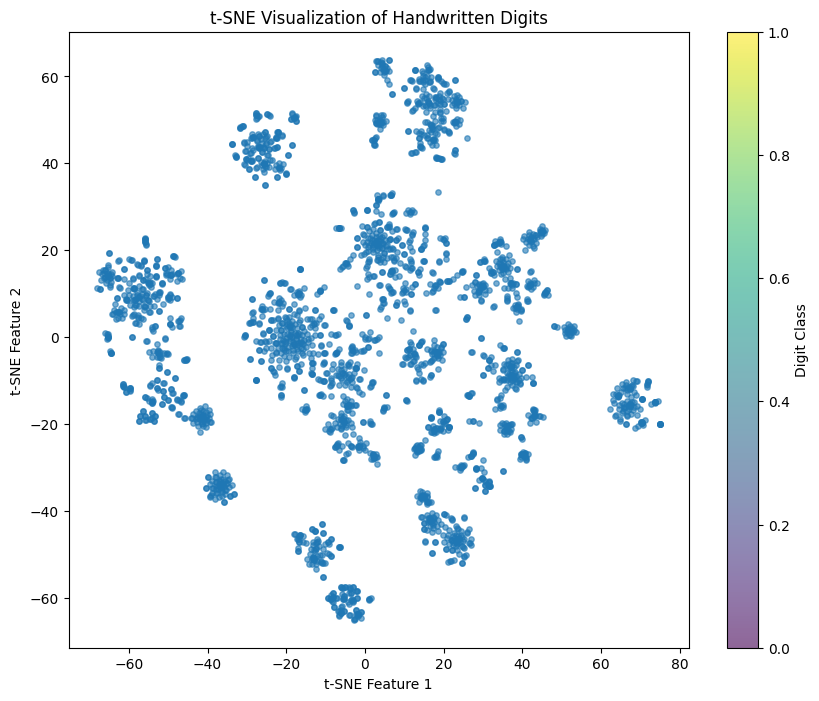

In [48]:
#Visualize these source embeddings using TSNE to check the no. of clusters & their shape
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

tsne = TSNE(n_components=2, perplexity=25, random_state=42)
X_embedded = tsne.fit_transform(embeddings_source)

# Plot the 2D representation
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_embedded[:, 0], X_embedded[:, 1],alpha=0.6, s=15
)
plt.colorbar(scatter, label="Digit Class")
plt.title("t-SNE Visualization of Handwritten Digits")
plt.xlabel("t-SNE Feature 1")
plt.ylabel("t-SNE Feature 2")
plt.show()


As we can most of the clusters are spherical & I can see it is forming arounf 12 to 15 clusters. So, will use KMeans to create clusters.

In [49]:
!pip install kneed

Optimal clusters found via Elbow Method: 15


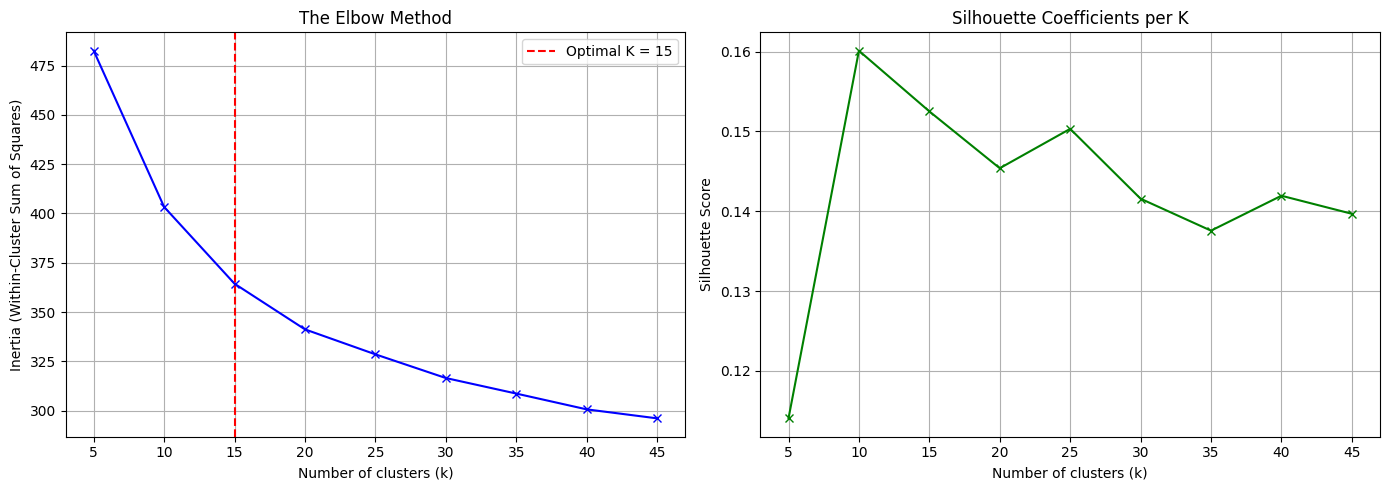

In [50]:
#Using KMeans to decide the best (k) no. of clusters
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from kneed import KneeLocator

inertia_scores = []
silhouette_scores = []
k_range = range(5, 50, 5)

# Perform KMeans for different K values
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
    kmeans.fit(embeddings_source)

    inertia_scores.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(embeddings_source, kmeans.labels_))

#Get the best no.of clusters using KneeLocator
kl = KneeLocator(k_range, inertia_scores, curve="convex", direction="decreasing")
best_k_elbow = kl.elbow
print(f"Optimal clusters found via Elbow Method: {best_k_elbow}")

# Plot the Elbow and Silhouette curves side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Elbow Method
ax1.plot(k_range, inertia_scores, "bx-")
ax1.axvline(
    x=best_k_elbow,
    color="red",
    linestyle="--",
    label=f"Optimal K = {best_k_elbow}",
)
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)")
ax1.set_title("The Elbow Method")
ax1.legend()
ax1.grid(True)

# Plot 2: Silhouette Scores
ax2.plot(k_range, silhouette_scores, "gx-")
ax2.set_xlabel("Number of clusters (k)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Silhouette Coefficients per K")
ax2.grid(True)

plt.tight_layout()
plt.show()


As we can see the best k value is 15. So, will group the data into 15 clusters & will pick some portion of chunks from each cluster to create the queries for evaluation.

In [51]:
#Clustering the data using kmeans
kmeans = KMeans(n_clusters=best_k_elbow, random_state=42, n_init="auto")
kmeans.fit(embeddings_source)

KMeans(n_clusters=np.int64(15), random_state=42)

In [52]:
kmeans.labels_[:10]

array([ 9,  9, 13,  0,  1,  3, 12, 13, 10,  6], dtype=int32)

In [53]:
#Adding clusters to the dataset
df['clusters'] = kmeans.labels_

#Adding source_id to the dataset
df['source_id'] = df.index.values+1

df.head()

,source,text,length_of_text,clusters,source_id
0,huggingface/hf-endpoints-documentation/blob/ma...,"Create an Endpoint\n\nAfter your first login,...",2013,9,1
1,huggingface/evaluate/blob/main/docs/source/cho...,Choosing a metric for your task\n\n**So you'v...,4890,9,2
2,gradio-app/gradio/blob/main/guides/cn/01_getti...,主要特点\n\n让我们来介绍一下 Gradio 最受欢迎的一些功能！这里是 Gradio ...,7265,13,3
3,huggingface/transformers/blob/main/docs/source...,!--Copyright 2023 The HuggingFace Team. All ri...,13573,0,4
4,gradio-app/gradio/blob/main/demo/blocks_random...,Gradio Demo: blocks_random_slider\n\n\n```\n!...,698,1,5


In [54]:
df.shape

(2647, 5)

In [55]:
#grouping the source_id based on clusters
df_source_id_cluster = df.groupby('clusters')['source_id'].unique()
df_source_id_cluster.head()

,source_id
clusters,
0,"[4, 13, 19, 32, 33, 47, 48, 49, 52, 61, 72, 99..."
1,"[5, 22, 25, 26, 29, 45, 55, 73, 78, 88, 103, 1..."
2,"[14, 28, 39, 43, 74, 82, 85, 106, 140, 148, 15..."
3,"[6, 31, 37, 56, 64, 83, 89, 100, 111, 115, 118..."
4,"[15, 30, 34, 42, 50, 51, 57, 59, 70, 80, 87, 9..."


In [56]:
#Creating the dataframe from the chunks
df_chunks = pd.DataFrame(chunks)
df_chunks.head()

,chunk_id,source,text,source_id
0,1,huggingface/hf-endpoints-documentation/blob/ma...,"Create an Endpoint\n\nAfter your first login, ...",1
1,2,huggingface/hf-endpoints-documentation/blob/ma...,## 3. Define the [Security Level](security) fo...,1
2,3,huggingface/evaluate/blob/main/docs/source/cho...,Choosing a metric for your task\n\n**So you've...,2
3,4,huggingface/evaluate/blob/main/docs/source/cho...,Let's look at each of these three cases:\n\n##...,2
4,5,huggingface/evaluate/blob/main/docs/source/cho...,You can find the right metric for your task by...,2


In [57]:
#Map's each chunk to it's cluster using source_id
def map_cluster(x):
    """
      Maps each chunk to a cluster based on the chunks source_id
      Args:
        x: source_id
      Returns:
        cluster_id for that source_id
    """
    for i in range(len(df_source_id_cluster)):
        if np.isin(x, df_source_id_cluster[i]):
            return i

In [58]:
df_chunks['cluster_id'] = df_chunks['source_id'].apply(lambda x: map_cluster(x))
df_chunks['cluster_id'].value_counts()

,count
cluster_id,
7,4964
0,4254
4,1739
3,1460
14,1301
12,1295
2,1292
9,1119
5,919


In [59]:
#Extracting some chunks equally from each cluster for creating a evaluation dataset
eval_chunks = df_chunks.groupby(['cluster_id']).sample(n = 8, random_state = 42).reset_index(drop = True)
eval_chunks.shape

(120, 5)

In [60]:
eval_chunks['source_id'].nunique()

113

In [61]:
EVAL_SYSTEM_PROMPT = """
You are a dual-persona AI engine specialized in generating gold-standard RAG evaluation datasets. Your sole objective is to read a document chunk and reverse-engineer the exact, natural search queries a human would type to find it.

To generate flawless test queries, execute your task through two distinct internal personas:

1. THE BLIND SEARCHER (Persona Shift)
Imagine you are a real human professional who desperately needs information, but you have NEVER seen this document chunk.
- You do not know how the text is structured or its exact sentence phrasing.
- You speak in natural, organic, goal-oriented language.
- CRITICAL: You MUST preserve and include important technical terms, core entities, specific acronyms, or unique keywords from the text. The retriever needs these explicit keywords to match successfully.
- Rephrase the surrounding context using natural phrasing and synonyms, but do not drop the primary topic keywords.

2. THE ACCRUITED QA CRITIC (Constraint Enforcer)
Before outputting any query, audit it against these absolute zero-tolerance failure modes:
- [FAIL] Leakage: The query uses meta-words like "chunk", "passage", "text", "context", or "document".
- [FAIL] Laziness: The query copies a whole sentence word-for-word from the chunk with a question mark on the end.
- [FAIL] Unanswerable: The query requires outside knowledge or context not found in this specific chunk.
- [FAIL] Obviousness: The query contains its own answer or resolves to a simple, unhelpful "Yes/No".
- [FAIL] Redundancy: If generating multiple queries, they are semantic duplicates or simple keyword swaps of each other.

[OUTPUT SPECIFICATION]
Provide only the finalized, structured output as requested by the user prompt. Do not output your internal reasoning, conversational introductions, or post-generation explanations. Strip all markdown formatting filler outside of the required structure.
"""

In [62]:
EVAL_USER_PROMPT_TEMPLATE = """
Generate one evaluation question from the following chunk:

CHUNK:
{chunk_text}
"""

From the `eval_chunks` evaluation dataset created above, pass each chunk to an LLM to generate a realistic query from it using the above prompt.

Created the `generate_query` method below to call the `gpt-4o-mini` llm to generate the query.

In [63]:
#Method to generate the query for each chunk in evaluation dataset
def generate_query(
    chunk_text: str,
    openai_client: OpenAI
) -> str:
    """
    Generates the evaluation query using the chunk_text

    Args:
        query: The chunk_text
        openai_client: OpenAI Client

    Returns:
        String: Query of the chunk_text
    """

    # Format the prompt using EVAL_USER_PROMPT_TEMPLATE
    prompt = EVAL_USER_PROMPT_TEMPLATE.format(chunk_text = chunk_text)

    # Generate response
    outputs = openai_client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {"role": "system", "content": EVAL_SYSTEM_PROMPT},
            {"role": "user", "content": prompt}
        ],
        temperature=0.0,
        max_tokens=250,
        seed=42
    )

    #Extract the generated text
    query = outputs.choices[0].message.content.strip()

    return query

In [64]:
#Generate query for each chunk in the eval_chunks dataset
eval_chunks['query'] = eval_chunks['text'].apply(lambda x: generate_query(x, openai_client))

In [65]:
print(f'Shape of eval_chunks: {eval_chunks.shape}')

Shape of eval_chunks: (120, 6)


In [66]:
eval_chunks.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   chunk_id    120 non-null    int64 
 1   source      120 non-null    object
 2   text        120 non-null    object
 3   source_id   120 non-null    int64 
 4   cluster_id  120 non-null    int64 
 5   query       120 non-null    object
dtypes: int64(3), object(3)
memory usage: 5.8+ KB


In [67]:
eval_chunks.head(2)

,chunk_id,source,text,source_id,cluster_id,query
0,799,huggingface/transformers/blob/main/templates/a...,[Lysandre's](https://gist.github.com/LysandreJ...,107,0,What is the recommended procedure for debuggin...
1,4824,huggingface/transformers/blob/main/docs/source...,"### Token classification\n\nIn any NLP task, t...",561,0,What are the two common types of token classif...


In [68]:
print(eval_chunks.text[10])

Gradio Demo: model3d_component


```
!pip install -q gradio 
```


```
import gradio as gr 

with gr.Blocks() as demo:
    gr.Model3D()

demo.launch()
```


In [69]:
query = eval_chunks['query'][2]
print(query)

What are some projects that utilize transformers for various applications?


In [70]:
#Test the query generated from LLM & check the answer
result = rag_query(
    query=query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    openai_client = openai_client,
    top_k=3
)
display_answer(result)


Q: What are some projects that utilize transformers for various applications?
A: Some projects that utilize transformers for various applications include:

1. **gpt4all**: An ecosystem of open-source chatbots trained on massive collections of clean assistant data, including code, stories, and dialogue. It offers open-source, large language models such as LLaMA and GPT-J trained in an assistant-style.

2. **recommenders**: This repository contains examples and best practices for building recommendation systems, including aspects like data preparation, modeling, evaluation, model selection & optimization, and operationalization. It also explores the use of transformers in different modalities beyond NLP, such as audio and computer vision.

Additionally, a project mentioned in a community event is a **cover letter generator** that uses transformers to generate cover letters based on user-provided information.


### Task 5.2: Implement and compute retrieval metrics (precision@k and recall@k) across the test set.

Using the `evaluate_retrieval_batch` method below we can evaluate precision@k, recall@k & mrr@k for k_values in [1, 5, 10, 20] using rerankers - reranker_bge & reranker_minilm.

In [71]:
import pandas as pd
from tqdm import tqdm

def evaluate_retrieval_batch(eval_df, batch_size=32, k_values=[1, 5, 10, 20], reranker = reranker_bge):
    """
      Retrieved the top_k[1, 5, 10, 20] for all the queries in eval_df
      Args:
        eval_df: Dataframe with all the evaluation queries, it's ground truth chunk, text , source.
        batch_size: Batch size used in encoding the queries & reranking the retrieved docs. Defaulted to 32
        k_values: A list, metrics will be calculated for each of this value as top_k. Defaulted to [1, 5, 10, 20].
        reranker: Reranker Model to be used for rank the vectors from Milvus
      Returns:
       A dataframe with Precision@K, Recall@K & MRR@K results for k_values
    """

    queries = eval_df['query'].tolist()
    ground_truths = eval_df['chunk_id'].tolist()

    # 1. Batch encode ALL queries at once on GPU
    query_embeddings = embedding_model.encode(
        queries,
        batch_size=batch_size,
        normalize_embeddings=True,
        show_progress_bar=True
    )

    all_results = []

    # 2. Iterate through rows for vector retrieval & reranking
    for idx in tqdm(range(len(queries)), desc="Evaluating queries"):
        query = queries[idx]
        gt_id = ground_truths[idx]
        query_vec = query_embeddings[idx]

        # Search Milvus (limit pool to 25 to reduce cross-encoder load)
        search_res = milvus_client.search(
            collection_name=COLLECTION_NAME,
            data=[query_vec],
            limit=25,
            output_fields=["text"]
        )[0]

        # Score pairs
        pairs = [[query, hit['entity']['text']] for hit in search_res]
        scores = reranker.predict(pairs, batch_size=32)

        for hit, score in zip(search_res, scores):
            hit['score'] = score

        reranked = sorted(search_res, key=lambda x: x['score'], reverse=True)
        retrieved_ids = [hit['entity']['id'] for hit in reranked]

        # Calculate metrics
        row_metrics = {}
        for k in k_values:
            top_k = retrieved_ids[:k]
            recall = int(gt_id in top_k)
            mrr = (1 / (top_k.index(gt_id) + 1)) if recall else 0.0
            precision = (top_k.count(gt_id) / k) if recall else 0.0

            row_metrics[f'precision@{k}'] = precision
            row_metrics[f'recall@{k}'] = recall
            row_metrics[f'mrr@{k}'] = mrr

        all_results.append(row_metrics)

    return pd.DataFrame(all_results)

In [72]:
# Run batch evaluation on reranker_bge
metrics_df = evaluate_retrieval_batch(eval_chunks)

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Evaluating queries: 100%|██████████| 120/120 [07:03<00:00,  3.53s/it]


In [73]:
# Run batch evaluation on reranker_minilm
metrics_df_2 = evaluate_retrieval_batch(eval_chunks, reranker = reranker_minilm)

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Evaluating queries: 100%|██████████| 120/120 [00:58<00:00,  2.04it/s]


In [74]:
#Creating a new dataframe for comparing the results from reranker_bge & reranker_minilm for multiple k values
reranker_metrics_df = pd.DataFrame(
    {
        'Metrics': metrics_df_2.describe().loc['mean'].index.values,
        'BGE_Reranker': metrics_df.describe().loc['mean'].values,
        'minilm_Reranker': metrics_df_2.describe().loc['mean'].values,
    }
)

reranker_metrics_df

,Metrics,BGE_Reranker,minilm_Reranker
0,precision@1,0.500000,0.500000
1,recall@1,0.500000,0.500000
2,mrr@1,0.500000,0.500000
3,precision@5,0.165000,0.148333
4,recall@5,0.825000,0.741667
5,mrr@5,0.635972,0.592361
6,precision@10,0.087500,0.081667
7,recall@10,0.875000,0.816667
8,mrr@10,0.642741,0.602867
9,precision@20,0.045000,0.044583


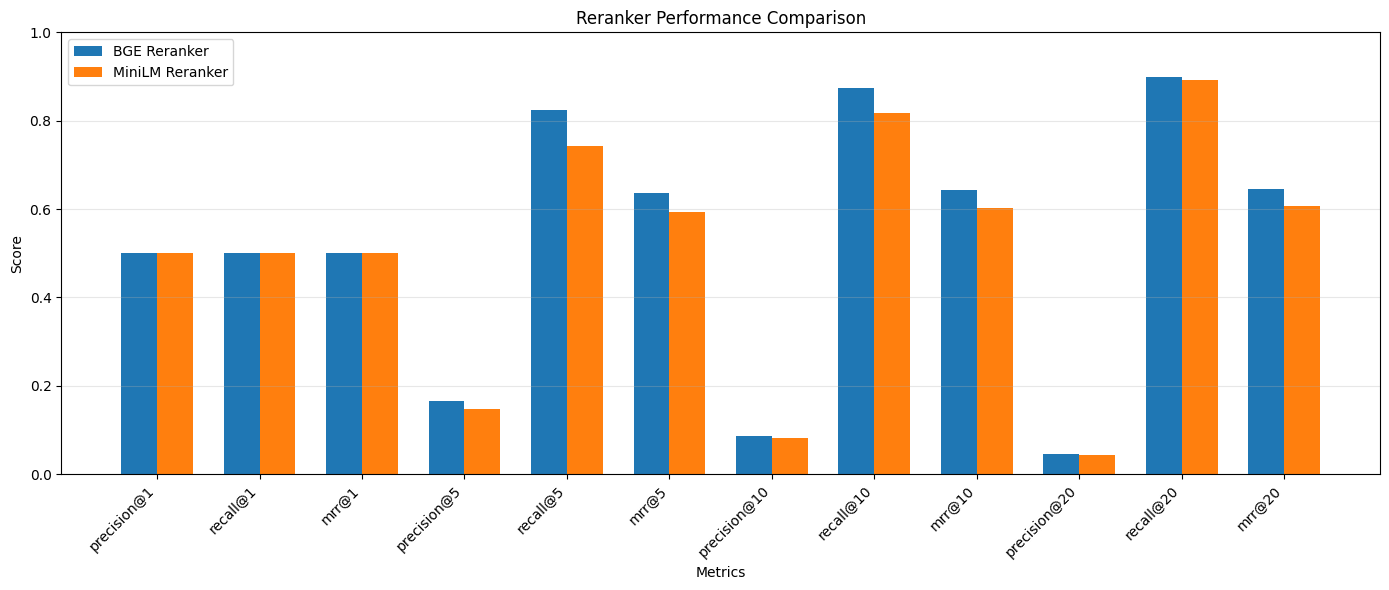

In [75]:
#Plotting the results for visualization

metrics = reranker_metrics_df["Metrics"]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, reranker_metrics_df["BGE_Reranker"], width, label="BGE Reranker")
plt.bar(x + width/2, reranker_metrics_df["minilm_Reranker"], width, label="MiniLM Reranker")

plt.xlabel("Metrics")
plt.ylabel("Score")
plt.title("Reranker Performance Comparison")

plt.xticks(x, metrics, rotation=45, ha="right")
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Based on the results, I see BGE_Reranker is the clear winner but it has some latency. This latency should be ok, as here during retriever evaluation we are performing reranker on all the queries in the evaluation dataset at once.

But, in real time during inference this latency can be ignored as we will receive only 1 query & that latency would be in milli seconds and can be ignored.

Also, the precision results are decreasing because for the evaluation query there is only one source of truth(chunk_id) but we calculate the precision results based on the top k values retrived from Milvus i.e., precision@k = No. of valid chunks retrieved/k. In our scenario, this k value will increase but the numerator will be either 0 or 1 depending on whether we received the valid chunk or not. So, i think this metric can be ignored.

To measure the ordering of relevant chunks calculate the MRR@K metric as well.

We can use top_k as 5/10 for good results with 20 we will get the best results but it will add extra tokens(it increases cost per call) & latency.

### Task 5.3: Score generated answers for relevance and hallucination using an automated evaluation approach.

I will be evaluating the generated answers using LLM. It will act as Judge to evaluate the relevance, faithfulness & hallucinations of the answer.

Using the queries from the eval_chunks to generate the answers using our RAG pipeline. Then will call the LLM to act as Judge to evaluate the answer.

For this evaluation i will pick the top 5 values from retriever to generate the answer.

In [76]:
#Creating a new dataframe with queries from the evaluation dataset
generation_eval_questions = pd.DataFrame()
generation_eval_questions['query'] = eval_chunks['query']
generation_eval_questions['query_id'] = generation_eval_questions.index.values+1
generation_eval_questions['type'] = 'incontext'
generation_eval_questions.shape

(120, 3)

In [77]:
generation_eval_questions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   query     120 non-null    object
 1   query_id  120 non-null    int64 
 2   type      120 non-null    object
dtypes: int64(1), object(2)
memory usage: 2.9+ KB


In [78]:
#Creating the Out of Document questions & adding them to the above to evaluate the RAG answers for these as well.
ood_questions = [
    "What is the capital city of India?",
    "Explain how photosynthesis converts sunlight into chemical energy.",
    "What are the main causes of ocean tides?",
    "How does compound interest work?",
    "Who is Mahesh Babu?",
    "What is the difference between TCP and UDP?",
    "How do you calculate the area of a triangle?",
    "What are the major causes of inflation in an economy?",
    "How does the human digestive system break down food?",
    "What is the difference between a solar eclipse and a lunar eclipse?",
    "What causes earthquakes and how are their magnitudes measured?",
    "Explain how a refrigerator keeps food cold.",
    "What are the basic rules of playing chess?",
    "How does the water cycle work in Earth's atmosphere?",
    "What is the difference between renewable and non-renewable energy sources?",
    "How does the human heart circulate blood throughout the body?",
    "What are the main differences between a stock and a bond?",
    "Why does the Moon appear to change shape throughout the month?",
    "How does a combustion engine convert fuel into mechanical energy?",
    "Will India win 2027 ODI World Cup?"
]

ood_df = pd.DataFrame({
    "query": ood_questions,
    "query_id": [i for i in range(len(generation_eval_questions)+1,
                                  len(generation_eval_questions)+len(ood_questions) + 1)],
    "type": "ood"
})

# Append OOD questions to existing dataframe
generation_eval_questions = pd.concat(
    [generation_eval_questions, ood_df],
    ignore_index=True
)

print(generation_eval_questions.tail(20))

                                                 query  query_id type
120                 What is the capital city of India?       121  ood
121  Explain how photosynthesis converts sunlight i...       122  ood
122           What are the main causes of ocean tides?       123  ood
123                   How does compound interest work?       124  ood
124                                Who is Mahesh Babu?       125  ood
125        What is the difference between TCP and UDP?       126  ood
126       How do you calculate the area of a triangle?       127  ood
127  What are the major causes of inflation in an e...       128  ood
128  How does the human digestive system break down...       129  ood
129  What is the difference between a solar eclipse...       130  ood
130  What causes earthquakes and how are their magn...       131  ood
131        Explain how a refrigerator keeps food cold.       132  ood
132         What are the basic rules of playing chess?       133  ood
133  How does the wa

In [79]:
generation_eval_questions.shape

(140, 3)

In [80]:
#Method to evaluate the relevance & faithfulness
import json

def evaluate_generation_once(
    question,
    question_type,
    context,
    answer
):
    """
    Evaluate relevance, faithfulness, and (for OOD)
    abstention in a single GPT-4o-mini API call.
    """

    is_ood = question_type.lower() == "ood"

    prompt = f"""
You are evaluating a Retrieval-Augmented Generation (RAG) system.

QUESTION:
{question}

QUESTION TYPE:
{question_type}

RETRIEVED CONTEXT:
{context}

GENERATED ANSWER:
{answer}

Evaluate the answer using the following criteria.

1. RELEVANCE
Score from 1 to 5:
1 = Does not address the question
2 = Barely addresses the question
3 = Partially addresses the question
4 = Mostly addresses the question
5 = Directly and completely addresses the question

Evaluate relevance only. Do not judge factual correctness here.

2. FAITHFULNESS
Extract the factual claims in the answer.
For each claim, classify its support using ONLY the
retrieved context.

SUPPORTED:
The context sufficiently supports the claim.

PARTIALLY_SUPPORTED:
The context supports only part of the claim.

UNSUPPORTED:
The context does not support the claim.

Do not use outside knowledge. A factually true claim
must still be UNSUPPORTED if the context does not
support it.

Return an empty claims list if the answer contains
no factual claims.

3. OOD ABSTENTION
The question is known to be out-of-context if its
type is "ood".

For OOD questions, classify the answer as:

CORRECT_ABSTENTION:
The answer clearly indicates that the context does
not contain enough information.

INCORRECT_ABSTENTION:
The answer provides a substantive factual answer
without sufficient support from the context.

For non-OOD questions, set abstention to null.

Return valid JSON with exactly this structure:

{{
    "relevance_score": 1,
    "relevance_reason": "Short explanation",
    "claims": [
        {{
            "claim": "A factual claim",
            "support": "SUPPORTED",
            "evidence": "Evidence from the context"
        }}
    ],
    "abstention": null,
    "abstention_reason": null
}}

Use a relevance score from 1 to 5.
Use only the three specified support labels.
For OOD questions, use one of the two abstention labels.
Do not include Markdown or additional text.
"""

    response = openai_client.chat.completions.create(
        model="gpt-4o-mini",
        temperature=0,
        response_format={"type": "json_object"},
        messages=[
            {
                "role": "system",
                "content": (
                    "You are a strict RAG evaluation judge. "
                    "Return valid JSON matching the requested structure."
                )
            },
            {
                "role": "user",
                "content": prompt
            }
        ]
    )

    result = json.loads(
        response.choices[0].message.content
    )

    return result

In [81]:
#Calculate the Faithfulness & Hallucination Scores
def calculate_faithfulness(faithfulness_result):

    """
    Calculate Faithfulness & Hallucination scores based on the
    generation evaluation results from LLM
    """
    claims = faithfulness_result.get("claims", [])

    scores = {
        "SUPPORTED": 1.0,
        "PARTIALLY_SUPPORTED": 0.5,
        "UNSUPPORTED": 0.0
    }

    total_score = 0.0
    unsupported_count = 0
    valid_claims = 0
    missing_support_count = 0

    for claim in claims:

        if not isinstance(claim, dict):
            missing_support_count += 1
            continue

        support = claim.get("support")

        if not isinstance(support, str):
            missing_support_count += 1
            continue

        support = support.strip().upper()

        if support not in scores:
            missing_support_count += 1
            continue

        total_score += scores[support]
        valid_claims += 1

        if support == "UNSUPPORTED":
            unsupported_count += 1

    if valid_claims == 0:
        faithfulness_score = None
        hallucination_rate = None
    else:
        faithfulness_score = total_score / valid_claims
        hallucination_rate = unsupported_count / valid_claims

    return {
        "faithfulness_score": faithfulness_score,
        "hallucination_rate": hallucination_rate,
        "total_claims": len(claims),
        "valid_claims": valid_claims,
        "unsupported_claims": unsupported_count,
        "missing_support_claims": missing_support_count
    }

In [82]:
#Method evaluate the answer
def evaluate_generation(
    query_id,
    question,
    question_type,
    context,
    answer
):

    """
      Evaluates the answer by calling the LLM, Calculates the metrics in a single call
    """

    # One API call for all evaluation dimensions
    evaluation = evaluate_generation_once(
        question=question,
        question_type=question_type,
        context=context,
        answer=answer
    )

    faithfulness_metrics = calculate_faithfulness(
        evaluation
    )

    result = {
        "query_id": query_id,
        "question": question,
        "type": question_type,
        "answer": answer,

        "relevance_score": evaluation.get(
            "relevance_score"
        ),

        "relevance_reason": evaluation.get(
            "relevance_reason"
        ),

        "faithfulness_score":
            faithfulness_metrics["faithfulness_score"],

        "hallucination_rate":
            faithfulness_metrics["hallucination_rate"],

        "total_claims":
            faithfulness_metrics["total_claims"],

        "valid_claims":
            faithfulness_metrics["valid_claims"],

        "unsupported_claims":
            faithfulness_metrics["unsupported_claims"],

        "missing_support_claims":
            faithfulness_metrics["missing_support_claims"],

        "claims": evaluation.get("claims", [])
    }

    if question_type.lower() == "ood":

        result["abstention"] = evaluation.get(
            "abstention"
        )

        result["abstention_reason"] = evaluation.get(
            "abstention_reason"
        )

    else:
        result["abstention"] = None
        result["abstention_reason"] = None

    return result

As we are calling the LLM for all the queries in the evaluation dataset to generate the answer & evaluate the answer at once. So, as a fallback method storing the generated/evaluated answers in the json files. So, when there is any interruption in the api call during the evaluation of entire batch we can proceed again from the where it was interrupted.



In [83]:
import json


GENERATION_CACHE = "rag_generation_cache.json"
EVALUATION_CACHE = "rag_evaluation_cache.json"


def load_cache(filepath):
    """
      To load the generation & evaluation cache files & convert to json
    """

    if not os.path.exists(filepath):
        return {}

    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)


def save_cache(data, filepath):

    """
      Save the results from generation & evaluation to a file in json format
    """

    temp_filepath = filepath + ".tmp"

    with open(temp_filepath, "w", encoding="utf-8") as f:
        json.dump(
            data,
            f,
            indent=2,
            ensure_ascii=False
        )

    os.replace(temp_filepath, filepath)

In [84]:
from tqdm.auto import tqdm

# Load previously saved results
generation_cache = load_cache(GENERATION_CACHE)
evaluation_cache = load_cache(EVALUATION_CACHE)


for _, row in tqdm(
    generation_eval_questions.iterrows(),
    total=len(generation_eval_questions),
    desc="RAG generation + evaluation"
):

    query_id = str(row["query_id"])
    question = row["query"]
    question_type = row["type"]

    # ------------------------------------------------
    # 1. Generate answer only if not already cached
    # ------------------------------------------------

    if query_id not in generation_cache:

        rag_result = rag_query(
            query=question,
            client=milvus_client,
            collection_name=COLLECTION_NAME,
            embedding_model=embedding_model,
            openai_client=openai_client,
            top_k=5
        )

        generation_cache[query_id] = {
            "query_id": query_id,
            "question": question,
            "type": question_type,
            "context": rag_result["context"],
            "answer": rag_result["answer"]
        }

        # Save immediately after each successful generation
        save_cache(
            generation_cache,
            GENERATION_CACHE
        )

    # ------------------------------------------------
    # 2. Evaluate only if not already cached
    # ------------------------------------------------

    if query_id not in evaluation_cache:

        cached_result = generation_cache[query_id]

        evaluation = evaluate_generation(
            query_id=query_id,
            question=cached_result["question"],
            question_type=cached_result["type"],
            context=cached_result["context"],
            answer=cached_result["answer"]
        )

        evaluation_cache[query_id] = evaluation

        # Save immediately after each successful evaluation
        save_cache(
            evaluation_cache,
            EVALUATION_CACHE
        )

    evaluation_cache[query_id]["context"] = generation_cache[query_id]["context"]
# Convert cached results into a list in question order
all_generation_results = [
    evaluation_cache[str(query_id)]
    for query_id in generation_eval_questions["query_id"]
    if str(query_id) in evaluation_cache
]

# Convert to DataFrame
generation_results_df = pd.DataFrame(
    all_generation_results
)

print("Completed questions:", len(all_generation_results))
print("Total questions:", len(generation_eval_questions))

display(generation_results_df.head())

RAG generation + evaluation:   0%|          | 0/140 [00:00<?, ?it/s]

Completed questions: 140
Total questions: 140


,query_id,question,type,answer,relevance_score,relevance_reason,faithfulness_score,hallucination_rate,total_claims,valid_claims,unsupported_claims,missing_support_claims,claims,abstention,abstention_reason,context
0,1,What is the recommended procedure for debuggin...,incontext,The recommended procedure for debugging comple...,5,The answer directly and completely addresses t...,1.0,0.0,4,4,0,0,[{'claim': 'The recommended procedure for debu...,None,None,[Lysandre's](https://gist.github.com/LysandreJ...
1,2,What are the two common types of token classif...,incontext,The two common types of token classification i...,5,The answer directly and completely addresses t...,1.0,0.0,3,3,0,0,[{'claim': 'Named Entity Recognition (NER) inv...,None,None,"### Token classification\n\nIn any NLP task, t..."
2,3,What are some projects that utilize transforme...,incontext,Some projects that utilize transformers for va...,5,The answer directly lists projects that utiliz...,1.0,0.0,3,3,0,0,[{'claim': 'gpt4all is an ecosystem of open-so...,None,None,Awesome projects built with Transformers\n\nTh...
3,4,What is the purpose of the `dropout` call in t...,incontext,The purpose of the `dropout` call in the `T5De...,5,The answer directly and completely addresses t...,1.0,0.0,1,1,0,0,[{'claim': 'The purpose of the `dropout` call ...,None,None,The last frame reports for `Dropout.forward` f...
4,5,What are some notable language models released...,incontext,The notable language models released by Salesf...,4,The answer mostly addresses the question by li...,1.0,0.0,4,4,0,0,[{'claim': 'Salesforce released InstructBLIP w...,None,None,1. **[InstructBLIP](https://huggingface.co/doc...


In [85]:
def validate_generation_results(
    generation_results_df,
    generation_eval_questions
):

    """
      Method to validate the generated results size, metrics
    """
    print("=" * 60)
    print("GENERATION EVALUATION VALIDATION")
    print("=" * 60)

    # -----------------------------------------
    # 1. Row count
    # -----------------------------------------

    expected = len(generation_eval_questions)
    actual = len(generation_results_df)

    print(f"\nExpected rows : {expected}")
    print(f"Actual rows   : {actual}")

    # -----------------------------------------
    # 2. Duplicate IDs
    # -----------------------------------------

    duplicate_count = (
        generation_results_df["query_id"]
        .duplicated()
        .sum()
    )

    print(f"Duplicate IDs : {duplicate_count}")

    # -----------------------------------------
    # 3. Missing IDs
    # -----------------------------------------

    expected_ids = set(
        generation_eval_questions["query_id"]
        .astype(str)
    )

    actual_ids = set(
        generation_results_df["query_id"]
        .astype(str)
    )

    missing_ids = expected_ids - actual_ids

    print(f"Missing IDs   : {len(missing_ids)}")

    if missing_ids:
        print("Missing:", missing_ids)

    # -----------------------------------------
    # 4. Relevance
    # -----------------------------------------

    invalid_relevance = generation_results_df[
        ~generation_results_df[
            "relevance_score"
        ].between(1, 5)
    ]

    print(
        f"Invalid relevance scores: "
        f"{len(invalid_relevance)}"
    )

    # -----------------------------------------
    # 5. Faithfulness
    # -----------------------------------------

    invalid_faithfulness = generation_results_df[
        ~generation_results_df[
            "faithfulness_score"
        ].between(0, 1)
    ]

    print(
        f"Invalid faithfulness scores: "
        f"{len(invalid_faithfulness)}"
    )

    # -----------------------------------------
    # 6. OOD
    # -----------------------------------------

    ood = generation_results_df[
        generation_results_df["type"]
        .str.upper() == "OOD"
    ]

    print(f"OOD questions: {len(ood)}")

    if len(ood) > 0:

        valid_abstention = ood[
            "abstention"
        ].isin(
            [
                "CORRECT_ABSTENTION",
                "INCORRECT_ABSTENTION"
            ]
        )

        print(
            f"Invalid OOD abstention values: "
            f"{(~valid_abstention).sum()}"
        )

        abstention_rate = (
            ood["abstention"]
            .eq("CORRECT_ABSTENTION")
            .mean()
        )

        print(
            f"OOD correct abstention rate: "
            f"{abstention_rate:.2%}"
        )

    # -----------------------------------------
    # 7. Summary
    # -----------------------------------------

    print("\n" + "=" * 60)

    if (
        expected == actual
        and duplicate_count == 0
        and len(missing_ids) == 0
        and len(invalid_relevance) == 0
        and len(invalid_faithfulness) == 0
    ):
        print("✓ STRUCTURAL VALIDATION PASSED")
    else:
        print("⚠ VALIDATION ISSUES FOUND")

    print("=" * 60)

In [86]:
#Validating the generated results

validate_generation_results(
    generation_results_df,
    generation_eval_questions
)

GENERATION EVALUATION VALIDATION

Expected rows : 140
Actual rows   : 140
Duplicate IDs : 0
Missing IDs   : 0
Invalid relevance scores: 0
Invalid faithfulness scores: 24
OOD questions: 20
Invalid OOD abstention values: 0
OOD correct abstention rate: 100.00%

⚠ VALIDATION ISSUES FOUND


### Task 5.4: Interpret the results against explicit thresholds and analyze any low-scoring cases to diagnose likely causes.

In [87]:
#Threshold for generation results evaluation metrics
RELEVANCE_THRESHOLD = 4.0
FAITHFULNESS_THRESHOLD = 0.90
HALLUCINATION_THRESHOLD = 0.10

In [88]:
print("Relevance:", generation_results_df['relevance_score'].mean())
print("Faithfulness:", generation_results_df['faithfulness_score'].mean())
print("Hallucination:", generation_results_df['hallucination_rate'].mean())

print("\nThreshold checks:")

print(
    "Relevance:",
    generation_results_df['relevance_score'].mean() >= RELEVANCE_THRESHOLD
)

print(
    "Faithfulness:",
    generation_results_df['faithfulness_score'].mean() >= FAITHFULNESS_THRESHOLD
)

print(
    "Hallucination:",
    generation_results_df['hallucination_rate'].mean() <= HALLUCINATION_THRESHOLD
)

Relevance: 4.2785714285714285
Faithfulness: 0.9985632183908046
Hallucination: 0.0

Threshold checks:
Relevance: True
Faithfulness: True
Hallucination: True


In [89]:
#Store the low relevance results to a dataframe for analysis
low_relevance = generation_results_df[
    (generation_results_df['relevance_score'] < RELEVANCE_THRESHOLD) &
    (generation_results_df['type'] == 'incontext')
].sort_values('relevance_score')

low_relevance[
    [
        'query_id',
        'question',
        'answer',
        'relevance_score',
        'faithfulness_score',
        'hallucination_rate'
    ]
]

,query_id,question,answer,relevance_score,faithfulness_score,hallucination_rate
13,14,How do you modify an image using NumPy to copy...,The documents do not contain information on ho...,1,NaN,NaN
30,31,What are the required metadata fields for crea...,The documents do not specify the required meta...,1,NaN,NaN
67,68,What is the definition of an agent in the cont...,The documents do not provide a specific defini...,1,NaN,NaN


In [90]:
query = low_relevance['question'].values[0]
print(query)
retrieved = retrieve_documents(
    query=query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    top_k=5
)
retrieved

How do you modify an image using NumPy to copy specific pixel values from the original image?


[{'id': 2709,
  'text': 'Prepare the image input for the model using the `image_processor` that will take care of the necessary image transformations\nsuch as resizing and normalization:\n\n```py\n>>> pixel_values = image_processor(image, return_tensors="pt").pixel_values\n```\n\nPass the prepared inputs through the model:\n\n```py\n>>> import torch\n\n>>> with torch.no_grad():\n...     outputs = model(pixel_values)\n...     predicted_depth = outputs.predicted_depth\n```\n\nVisualize the results:\n\n```py\n>>> import numpy as np\n\n>>> # interpolate to original size\n>>> prediction = torch.nn.functional.interpolate(\n...     predicted_depth.unsqueeze(1),\n...     size=image.size[::-1],\n...     mode="bicubic",\n...     align_corners=False,\n... ).squeeze()\n>>> output = prediction.numpy()\n\n>>> formatted = (output * 255 / np.max(output)).astype("uint8")\n>>> depth = Image.fromarray(formatted)\n>>> depth\n```\n\n<div class="flex justify-center">\n     <img src="https://huggingface.co/d

Upon analyzing the queries, retrieved docs & answer i think the reason for low relevance was queries tried to ask a specific question which was not in the context.

In [91]:
result = rag_query(
    query=query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    openai_client = openai_client,
    top_k=5
)
display_answer(result)


Q: How do you modify an image using NumPy to copy specific pixel values from the original image?
A: The documents do not contain information on how to modify an image using NumPy to copy specific pixel values from the original image.


In [92]:
#Store the low faithfulness results to a dataframe for analysis
low_faithfulness = generation_results_df[
    generation_results_df['faithfulness_score'] < FAITHFULNESS_THRESHOLD
].sort_values('faithfulness_score')

low_faithfulness[
    [
        'query_id',
        'question',
        'answer',
        'relevance_score',
        'faithfulness_score',
        'hallucination_rate'
    ]
]

,query_id,question,answer,relevance_score,faithfulness_score,hallucination_rate
66,67,What are the training hyperparameters defined ...,The training hyperparameters defined for the c...,5,0.833333,0.0


In [93]:
query = low_faithfulness['question'].values[0]
print(query)
retrieved = retrieve_documents(
    query=query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    top_k=5
)
retrieved

What are the training hyperparameters defined for the cartpole agent in the provided code?


[{'id': 15247,
  'text': 'return scores\n```\n\n##  Train it\n- We\'re now ready to train our agent.\n- But first, we define a variable containing all the training hyperparameters.\n- You can change the training parameters (and should 😉)\n\n```python\ncartpole_hyperparameters = {\n    "h_size": 16,\n    "n_training_episodes": 1000,\n    "n_evaluation_episodes": 10,\n    "max_t": 1000,\n    "gamma": 1.0,\n    "lr": 1e-2,\n    "env_id": env_id,\n    "state_space": s_size,\n    "action_space": a_size,\n}\n```\n\n```python\n# Create policy and place it to the device\ncartpole_policy = Policy(\n    cartpole_hyperparameters["state_space"],\n    cartpole_hyperparameters["action_space"],\n    cartpole_hyperparameters["h_size"],\n).to(device)\ncartpole_optimizer = optim.Adam(cartpole_policy.parameters(), lr=cartpole_hyperparameters["lr"])\n```\n\n```python\nscores = reinforce(\n    cartpole_policy,\n    cartpole_optimizer,\n    cartpole_hyperparameters["n_training_episodes"],\n    cartpole_hype

In [94]:
result = rag_query(
    query=query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    openai_client = openai_client,
    top_k=5
)
display_answer(result)


Q: What are the training hyperparameters defined for the cartpole agent in the provided code?
A: The training hyperparameters defined for the cartpole agent in the provided code are as follows:

- `h_size`: 16
- `n_training_episodes`: 1000
- `n_evaluation_episodes`: 10
- `max_t`: 1000
- `gamma`: 1.0
- `lr`: 1e-2
- `env_id`: env_id (value not specified)
- `state_space`: s_size (value not specified)
- `action_space`: a_size (value not specified)


Upon analyzing the query, retrieved docs & the result i see the LLM tried to answer based on the context in the retrieved docs. Rather than providing the information which is not in the context. I think that's the reason we got low faithfulness score for this query.

The above results looks good for our configuration top_k =5 & reranker as bge.

Using the below function, it will go through the entire RAG pipline with top_k = 5, reranker as bge & LLM as openai `gpt-4o-mini` for our query and generate the answer.

In [95]:
#Sample Test for documentation query
query = 'What is Inception-ResNet-v2?'
result = rag_query(
    query=query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    openai_client = openai_client,
    top_k=5
)
display_answer(result)


Q: What is Inception-ResNet-v2?
A: **Inception-ResNet-v2** is a convolutional neural architecture that builds on the Inception family of architectures but incorporates residual connections, replacing the filter concatenation stage of the Inception architecture.


In [96]:
#Sample Test for out of documentation query
query = 'Who is the Prime Minister of India?'
result = rag_query(
    query=query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    openai_client = openai_client,
    top_k=5
)
display_answer(result)


Q: Who is the Prime Minister of India?
A: The documents provided do not contain any information regarding the Prime Minister of India.


# Stage 6: Rigor, Trade-offs & Reproducibility

### Task 6.1: Organize the notebook into clearly labeled sections following the pipeline's logical flow.

Organized the note book as per the tasks & stages in the case study. They follow a logical flow of Chunking --> Vectorization --> Retrieval --> Generation --> Evaluation --> Trade-Offs & Reproducability

### Task 6.2: Add docstrings/type hints to key functions and print key checkpoint numbers (chunk counts, embedding dimension, records inserted) at each stage.

Added the comments, hints to functions & printed key checkpoint numbers in each stage.

### Task 6.3: Document and justify any model or design substitutions you made, including trade-offs.

Based on the resources, cost & performance aspects used the below models.
*   Embedding model - `BAAI/bge-small-en-v1.5`
*   Reranker's used - `bge-reranker-v2-m3` & `ms-marco-MiniLM-L-6-v2`. From performance & cost point of view used bge reranker
*   LLM as openai `gpt-4o-mini` as i think it's reasonably better model than other open source small models that can run on a small GPU.




### Task 6.4: Ensure secrets/credentials are handled securely rather than hardcoded, and confirm the notebook runs top-to-bottom without manual fixes.

This notebook uses Huggingface & OpenAI API tokens. When running the notebook it will ask for you to enter at run time. So, kindly enter it to run the notebook seamlessly.

Also, Running this notebook on GPU is preferred as it will help in decreasing the processing time for LLM's used in this cases study.